Cyber Fraud Intelligence & Threat Analytics

In [1]:

# ============================================================
# PROJECT 03 - CYBER FRAUD INTELLIGENCE & THREAT ANALYTICS
# Environment Setup
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from datetime import datetime

# Reproducibility
SEED = 42
np.random.seed(SEED)

# Display configuration
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Project parameters
N_EVENTS = 5000

print("=" * 60)
print("CYBER FRAUD INTELLIGENCE & THREAT ANALYTICS")
print("=" * 60)
print(f"Execution date: {datetime.now().strftime('%Y-%m-%d %H:%M')}")
print(f"Random seed: {SEED}")
print(f"Events to generate: {N_EVENTS:,}")
print("Environment successfully initialized.")


CYBER FRAUD INTELLIGENCE & THREAT ANALYTICS
Execution date: 2026-11-15 20:12
Random seed: 42
Events to generate: 5,000
Environment successfully initialized.


Geração da base de eventos

In [2]:

# ============================================================
# STEP 02 - SYNTHETIC CYBER THREAT DATA GENERATION
# ============================================================

N = N_EVENTS

threat_types = [
    "Account Takeover",
    "Credential Stuffing",
    "Phishing",
    "Malware",
    "Device Compromise",
    "Social Engineering",
    "Bot Attack",
    "Data Exfiltration"
]

severities = ["Low", "Medium", "High", "Critical"]

channels = [
    "Mobile Banking",
    "Internet Banking",
    "Digital Onboarding",
    "PIX",
    "Internal Systems"
]

sources = [
    "Foreign IP",
    "Proxy",
    "VPN",
    "TOR",
    "Residential IP",
    "Unknown"
]

df = pd.DataFrame({
    "event_id": range(1, N + 1),
    "threat_type": np.random.choice(threat_types, N),
    "severity": np.random.choice(
        severities, N, p=[0.30, 0.35, 0.25, 0.10]
    ),
    "channel": np.random.choice(channels, N),
    "source": np.random.choice(sources, N),
    "failed_attempts": np.random.poisson(3, N),
    "risk_indicator": np.random.randint(1, 101, N),
    "affected_accounts": np.random.poisson(2, N),
    "detection_time_minutes": np.random.randint(1, 181, N),
    "mitre_mapping": np.random.choice(
        ["T1566", "T1110", "T1078", "T1059", "T1041"],
        N
    )
})

# Preview dataset
print("Dataset generated successfully!")
print(f"Total events: {len(df):,}")
print("\nFirst 10 records:")

display(df.head(10))


Dataset generated successfully!
Total events: 5,000

First 10 records:


,event_id,threat_type,severity,channel,source,failed_attempts,risk_indicator,affected_accounts,detection_time_minutes,mitre_mapping
0,1,Bot Attack,High,PIX,Foreign IP,0,3,1,70,T1041
1,2,Malware,High,PIX,Foreign IP,1,77,2,179,T1078
2,3,Device Compromise,Medium,Internet Banking,TOR,4,38,4,30,T1059
3,4,Bot Attack,Critical,Internal Systems,Proxy,7,92,1,158,T1566
4,5,Phishing,Low,Mobile Banking,TOR,4,14,3,144,T1078
5,6,Data Exfiltration,Low,Mobile Banking,Unknown,2,1,1,151,T1059
6,7,Device Compromise,High,Internal Systems,Residential IP,2,92,1,159,T1078
7,8,Device Compromise,Medium,Internet Banking,Proxy,6,100,4,12,T1059
8,9,Bot Attack,High,Internet Banking,Residential IP,1,11,5,3,T1059
9,10,Credential Stuffing,High,Internet Banking,VPN,2,40,4,67,T1078


Análise exploratória e perfil das ameaças

CYBER THREAT LANDSCAPE

1. Threat distribution:


,Threat Type,Events,Percentage
0,Malware,657,13.14
1,Device Compromise,651,13.02
2,Account Takeover,644,12.88
3,Social Engineering,628,12.56
4,Credential Stuffing,612,12.24
5,Phishing,608,12.16
6,Bot Attack,601,12.02
7,Data Exfiltration,599,11.98



2. Severity distribution:


,Events
severity,
Low,1532
Medium,1770
High,1203
Critical,495



3. Threat x Severity:


severity,Critical,High,Low,Medium
threat_type,,,,
Account Takeover,66,162,197,219
Bot Attack,61,142,179,219
Credential Stuffing,50,146,182,234
Data Exfiltration,54,134,189,222
Device Compromise,69,169,197,216
Malware,73,163,206,215
Phishing,60,142,187,219
Social Engineering,62,145,195,226


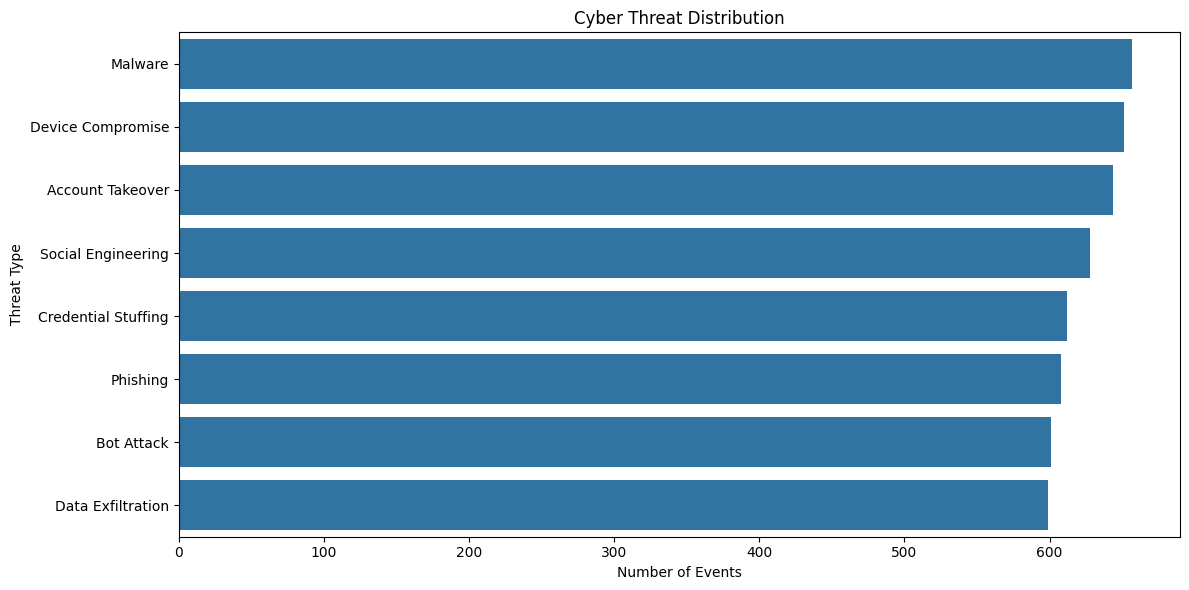


4. High and Critical events:
Total: 1,698
Percentage: 33.96%


In [3]:

# ============================================================
# STEP 03 - THREAT LANDSCAPE & EXPLORATORY ANALYSIS
# ============================================================

print("=" * 60)
print("CYBER THREAT LANDSCAPE")
print("=" * 60)

# 1. Threat distribution
threat_distribution = (
    df["threat_type"]
    .value_counts()
    .reset_index()
)

threat_distribution.columns = ["Threat Type", "Events"]

threat_distribution["Percentage"] = (
    threat_distribution["Events"] / len(df) * 100
).round(2)

print("\n1. Threat distribution:")
display(threat_distribution)

# 2. Severity distribution
severity_distribution = (
    df["severity"]
    .value_counts()
    .reindex(["Low", "Medium", "High", "Critical"])
    .fillna(0)
    .astype(int)
)

print("\n2. Severity distribution:")
display(severity_distribution.to_frame("Events"))

# 3. Threat x Severity
threat_severity = pd.crosstab(
    df["threat_type"],
    df["severity"]
)

print("\n3. Threat x Severity:")
display(threat_severity)

# 4. Executive visualization
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="threat_type",
    order=df["threat_type"].value_counts().index
)

plt.title("Cyber Threat Distribution")
plt.xlabel("Number of Events")
plt.ylabel("Threat Type")
plt.tight_layout()
plt.show()

# 5. High and Critical events
critical_events = df[
    df["severity"].isin(["High", "Critical"])
]

print("\n4. High and Critical events:")
print(f"Total: {len(critical_events):,}")
print(f"Percentage: {len(critical_events)/len(df)*100:.2f}%")


Cyber Risk Scoring Engine

In [4]:

# ============================================================
# STEP 04 - CYBER RISK SCORING ENGINE
# ============================================================

print("=" * 60)
print("CYBER RISK SCORING ENGINE")
print("=" * 60)

# 1. Severity mapping
severity_score = {
    "Low": 20,
    "Medium": 45,
    "High": 75,
    "Critical": 100
}

df["severity_score"] = df["severity"].map(severity_score)

# 2. Connection source risk
source_score = {
    "Foreign IP": 80,
    "Proxy": 85,
    "VPN": 65,
    "TOR": 100,
    "Residential IP": 20,
    "Unknown": 60
}

df["source_score"] = df["source"].map(source_score)

# 3. Normalize behavioral indicators
df["failed_attempts_score"] = (
    df["failed_attempts"].clip(upper=10) / 10 * 100
)

df["affected_accounts_score"] = (
    df["affected_accounts"].clip(upper=10) / 10 * 100
)

# 4. Calculate weighted risk score
df["risk_score"] = (
    df["risk_indicator"] * 0.35 +
    df["severity_score"] * 0.30 +
    df["failed_attempts_score"] * 0.15 +
    df["source_score"] * 0.10 +
    df["affected_accounts_score"] * 0.10
).round(2)

# 5. Risk classification
def classify_risk(score):
    if score >= 80:
        return "Critical"
    elif score >= 60:
        return "High"
    elif score >= 40:
        return "Medium"
    return "Low"

df["risk_classification"] = df["risk_score"].apply(
    classify_risk
)

# 6. Executive results
print("\nRisk classification:")
display(
    df["risk_classification"]
    .value_counts()
    .reindex(["Critical", "High", "Medium", "Low"])
    .fillna(0)
    .astype(int)
    .to_frame("Events")
)

print("\nTop 15 highest risk events:")

display(
    df.sort_values(
        "risk_score", ascending=False
    )[[
        "event_id",
        "threat_type",
        "severity",
        "source",
        "risk_indicator",
        "risk_score",
        "risk_classification"
    ]].head(15)
)

print("\nAverage risk score:", df["risk_score"].mean().round(2))


CYBER RISK SCORING ENGINE

Risk classification:


,Events
risk_classification,
Critical,16
High,776
Medium,2506
Low,1702



Top 15 highest risk events:


,event_id,threat_type,severity,source,risk_indicator,risk_score,risk_classification
234,235,Malware,Critical,TOR,96,90.60,Critical
3973,3974,Bot Attack,Critical,TOR,94,86.90,Critical
1567,1568,Malware,Critical,Proxy,90,86.00,Critical
931,932,Malware,Critical,Foreign IP,96,83.10,Critical
1073,1074,Phishing,Critical,Foreign IP,90,83.00,Critical
2665,2666,Device Compromise,Critical,Proxy,95,82.75,Critical
1015,1016,Social Engineering,Critical,Foreign IP,94,82.40,Critical
3,4,Bot Attack,Critical,Proxy,92,82.20,Critical
2704,2705,Malware,Critical,Proxy,90,82.00,Critical
943,944,Device Compromise,Critical,TOR,99,81.65,Critical



Average risk score: 46.04


MITRE ATT&CK Mapping

In [5]:

# ============================================================
# STEP 05 - MITRE ATT&CK THREAT MAPPING
# ============================================================

print("=" * 60)
print("MITRE ATT&CK THREAT INTELLIGENCE")
print("=" * 60)

# Candidate mappings based on threat context
mitre_mapping = {
    "Account Takeover": {
        "technique": "T1078",
        "name": "Valid Accounts",
        "status": "Candidate",
        "rationale": "Use of compromised valid accounts."
    },
    "Credential Stuffing": {
        "technique": "T1110.004",
        "name": "Credential Stuffing",
        "status": "Candidate",
        "rationale": "Automated use of previously exposed credentials."
    },
    "Phishing": {
        "technique": "T1566",
        "name": "Phishing",
        "status": "Candidate",
        "rationale": "Credential or information collection through phishing."
    },
    "Data Exfiltration": {
        "technique": "T1041",
        "name": "Exfiltration Over C2 Channel",
        "status": "Conditional",
        "rationale": "Applies when exfiltration uses a command and control channel."
    },
    "Malware": {
        "technique": None,
        "name": "Requires investigation",
        "status": "Needs context",
        "rationale": "Malware behavior must be analyzed to identify its techniques."
    },
    "Device Compromise": {
        "technique": None,
        "name": "Requires investigation",
        "status": "Needs context",
        "rationale": "Device compromise can involve multiple ATT&CK techniques."
    },
    "Social Engineering": {
        "technique": None,
        "name": "Requires investigation",
        "status": "Needs context",
        "rationale": "Social engineering methods require additional context."
    },
    "Bot Attack": {
        "technique": None,
        "name": "Requires investigation",
        "status": "Needs context",
        "rationale": "Bot behavior alone does not identify a specific technique."
    }
}

# Apply mapping
df["mitre_technique_id"] = df["threat_type"].map(
    lambda x: mitre_mapping[x]["technique"]
)

df["mitre_technique_name"] = df["threat_type"].map(
    lambda x: mitre_mapping[x]["name"]
)

df["mitre_mapping_status"] = df["threat_type"].map(
    lambda x: mitre_mapping[x]["status"]
)

df["mitre_rationale"] = df["threat_type"].map(
    lambda x: mitre_mapping[x]["rationale"]
)

# Summary
print("\n1. MITRE mapping by threat type:")

mitre_summary = (
    df.groupby(
        ["threat_type", "mitre_technique_id",
         "mitre_technique_name", "mitre_mapping_status"],
        dropna=False
    )
    .size()
    .reset_index(name="event_count")
    .sort_values("event_count", ascending=False)
)

display(mitre_summary)

# Mapping coverage
print("\n2. Mapping coverage:")

display(
    df["mitre_mapping_status"]
    .value_counts()
    .to_frame("Events")
)

# High risk events with MITRE context
print("\n3. High-risk threat intelligence:")

display(
    df.sort_values("risk_score", ascending=False)[
        [
            "event_id",
            "threat_type",
            "severity",
            "risk_score",
            "risk_classification",
            "mitre_technique_id",
            "mitre_technique_name",
            "mitre_mapping_status"
        ]
    ].head(15)
)


MITRE ATT&CK THREAT INTELLIGENCE

1. MITRE mapping by threat type:


,threat_type,mitre_technique_id,mitre_technique_name,mitre_mapping_status,event_count
5,Malware,NaN,Requires investigation,Needs context,657
4,Device Compromise,NaN,Requires investigation,Needs context,651
0,Account Takeover,T1078,Valid Accounts,Candidate,644
7,Social Engineering,NaN,Requires investigation,Needs context,628
2,Credential Stuffing,T1110.004,Credential Stuffing,Candidate,612
6,Phishing,T1566,Phishing,Candidate,608
1,Bot Attack,NaN,Requires investigation,Needs context,601
3,Data Exfiltration,T1041,Exfiltration Over C2 Channel,Conditional,599



2. Mapping coverage:


,Events
mitre_mapping_status,
Needs context,2537
Candidate,1864
Conditional,599



3. High-risk threat intelligence:


,event_id,threat_type,severity,risk_score,risk_classification,mitre_technique_id,mitre_technique_name,mitre_mapping_status
234,235,Malware,Critical,90.60,Critical,None,Requires investigation,Needs context
3973,3974,Bot Attack,Critical,86.90,Critical,None,Requires investigation,Needs context
1567,1568,Malware,Critical,86.00,Critical,None,Requires investigation,Needs context
931,932,Malware,Critical,83.10,Critical,None,Requires investigation,Needs context
1073,1074,Phishing,Critical,83.00,Critical,T1566,Phishing,Candidate
2665,2666,Device Compromise,Critical,82.75,Critical,None,Requires investigation,Needs context
1015,1016,Social Engineering,Critical,82.40,Critical,None,Requires investigation,Needs context
3,4,Bot Attack,Critical,82.20,Critical,None,Requires investigation,Needs context
2704,2705,Malware,Critical,82.00,Critical,None,Requires investigation,Needs context
943,944,Device Compromise,Critical,81.65,Critical,None,Requires investigation,Needs context


NIST Cybersecurity Framework 2.0

In [6]:

# ============================================================
# STEP 06 - NIST CYBERSECURITY FRAMEWORK 2.0
# Control Mapping & Governance
# ============================================================

print("=" * 65)
print("NIST CYBERSECURITY FRAMEWORK - CONTROL MAPPING")
print("=" * 65)

# Threat-to-control mapping (illustrative)
nist_mapping = {
    "Account Takeover": {
        "function": "PROTECT",
        "category": "Identity Management",
        "control": "MFA and adaptive authentication",
        "action": "Strengthen account authentication"
    },
    "Credential Stuffing": {
        "function": "DETECT",
        "category": "Continuous Monitoring",
        "control": "Authentication anomaly detection",
        "action": "Monitor repeated login failures"
    },
    "Phishing": {
        "function": "PROTECT",
        "category": "Security Awareness",
        "control": "Email security and user awareness",
        "action": "Improve phishing prevention"
    },
    "Malware": {
        "function": "DETECT",
        "category": "Security Monitoring",
        "control": "Endpoint Detection and Response",
        "action": "Improve endpoint monitoring"
    },
    "Device Compromise": {
        "function": "PROTECT",
        "category": "Device Security",
        "control": "Device integrity and compliance",
        "action": "Strengthen device validation"
    },
    "Social Engineering": {
        "function": "PROTECT",
        "category": "Awareness and Training",
        "control": "Social engineering prevention",
        "action": "Improve employee awareness"
    },
    "Bot Attack": {
        "function": "DETECT",
        "category": "Network Monitoring",
        "control": "Behavioral analytics and bot detection",
        "action": "Identify automated activity"
    },
    "Data Exfiltration": {
        "function": "RESPOND",
        "category": "Incident Response",
        "control": "Data Loss Prevention and incident response",
        "action": "Contain and investigate data exposure"
    }
}

# Apply NIST mapping
df["nist_function"] = df["threat_type"].map(
    lambda x: nist_mapping[x]["function"]
)

df["nist_category"] = df["threat_type"].map(
    lambda x: nist_mapping[x]["category"]
)

df["recommended_control"] = df["threat_type"].map(
    lambda x: nist_mapping[x]["control"]
)

df["mitigation_action"] = df["threat_type"].map(
    lambda x: nist_mapping[x]["action"]
)

# 1. Distribution by NIST function
print("\n1. Events by NIST function:")

nist_summary = (
    df.groupby("nist_function")
    .agg(
        total_events=("event_id", "count"),
        average_risk=("risk_score", "mean"),
        critical_events=(
            "risk_classification",
            lambda x: x.isin(["Critical", "High"]).sum()
        )
    )
    .round(2)
    .sort_values("total_events", ascending=False)
)

display(nist_summary)

# 2. Threat and control matrix
print("\n2. Threat and recommended controls:")

control_matrix = (
    df.groupby(
        ["threat_type", "nist_function",
         "recommended_control", "mitigation_action"]
    )
    .size()
    .reset_index(name="event_count")
    .sort_values("event_count", ascending=False)
)

display(control_matrix)

# 3. Highest risk events and recommended actions
print("\n3. Priority remediation actions:")

priority_actions = (
    df[df["risk_classification"].isin(["Critical", "High"])]
    .groupby(
        ["threat_type", "nist_function",
         "recommended_control", "mitigation_action"]
    )
    .agg(
        events=("event_id", "count"),
        average_risk=("risk_score", "mean")
    )
    .round(2)
    .sort_values("average_risk", ascending=False)
)

display(priority_actions.head(15))

print("\nNIST mapping completed successfully!")


NIST CYBERSECURITY FRAMEWORK - CONTROL MAPPING

1. Events by NIST function:


,total_events,average_risk,critical_events
nist_function,,,
PROTECT,2531,46.25,402
DETECT,1870,45.91,303
RESPOND,599,45.49,87



2. Threat and recommended controls:


,threat_type,nist_function,recommended_control,mitigation_action,event_count
5,Malware,DETECT,Endpoint Detection and Response,Improve endpoint monitoring,657
4,Device Compromise,PROTECT,Device integrity and compliance,Strengthen device validation,651
0,Account Takeover,PROTECT,MFA and adaptive authentication,Strengthen account authentication,644
7,Social Engineering,PROTECT,Social engineering prevention,Improve employee awareness,628
2,Credential Stuffing,DETECT,Authentication anomaly detection,Monitor repeated login failures,612
6,Phishing,PROTECT,Email security and user awareness,Improve phishing prevention,608
1,Bot Attack,DETECT,Behavioral analytics and bot detection,Identify automated activity,601
3,Data Exfiltration,RESPOND,Data Loss Prevention and incident response,Contain and investigate data exposure,599



3. Priority remediation actions:


,,,,events,average_risk
threat_type,nist_function,recommended_control,mitigation_action,,
Bot Attack,DETECT,Behavioral analytics and bot detection,Identify automated activity,90,67.65
Device Compromise,PROTECT,Device integrity and compliance,Strengthen device validation,112,67.40
Malware,DETECT,Endpoint Detection and Response,Improve endpoint monitoring,116,67.15
Account Takeover,PROTECT,MFA and adaptive authentication,Strengthen account authentication,92,67.14
Phishing,PROTECT,Email security and user awareness,Improve phishing prevention,95,66.54
Data Exfiltration,RESPOND,Data Loss Prevention and incident response,Contain and investigate data exposure,87,66.33
Credential Stuffing,DETECT,Authentication anomaly detection,Monitor repeated login failures,97,66.08
Social Engineering,PROTECT,Social engineering prevention,Improve employee awareness,103,65.85



NIST mapping completed successfully!


Executive Cyber Risk Dashboard

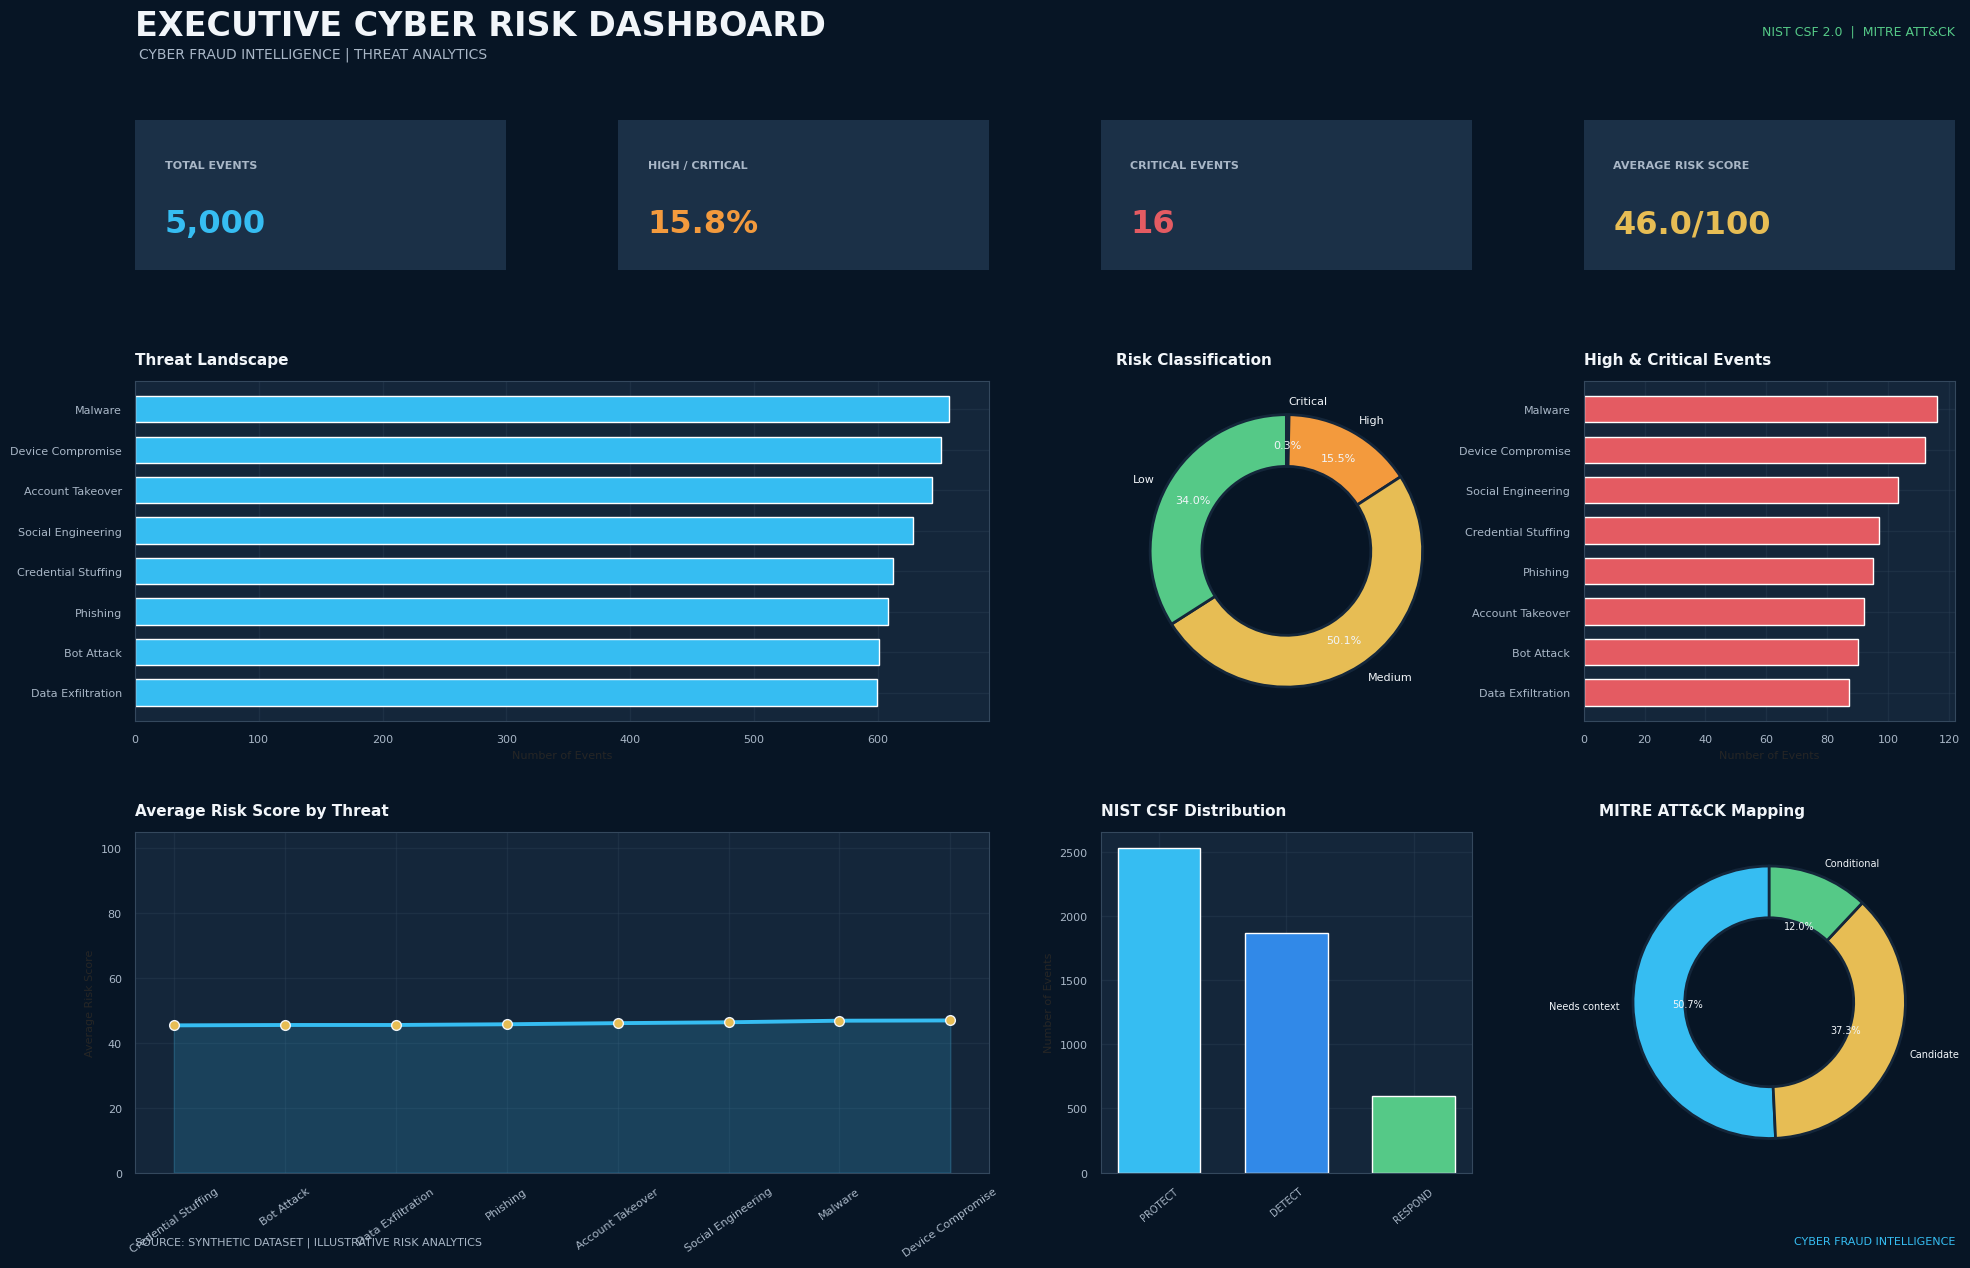

EXECUTIVE CYBER RISK DASHBOARD
Total events: 5,000
High / Critical: 792 (15.8%)
Critical events: 16
Average risk score: 46.04
MITRE candidate mappings: 0
Dashboard exported successfully.
File: executive_cyber_risk_dashboard.png


In [14]:

# ============================================================
# EXECUTIVE CYBER RISK DASHBOARD
# Dark Corporate Theme | Cyber Fraud Intelligence
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch

# ============================================================
# 1. IDENTIDADE VISUAL
# ============================================================

BG = "#071525"
PANEL = "#14263A"
PANEL_LIGHT = "#1B3047"
BORDER = "#34485D"

WHITE = "#F1F5F9"
MUTED = "#A9B7C7"

CYAN = "#36BDF2"
BLUE = "#3189E8"
GOLD = "#E7BD54"
GREEN = "#55C987"
ORANGE = "#F39A3D"
RED = "#E45B62"

COLORS = [RED, ORANGE, GOLD, GREEN]

# ============================================================
# 2. VALIDAR DADOS
# ============================================================

required_columns = [
    "threat_type",
    "risk_classification",
    "risk_score",
    "nist_function",
    "mitre_mapping_status"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in dataframe: {missing_columns}"
    )

# ============================================================
# 3. CONFIGURAÇÃO GLOBAL
# ============================================================

plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": PANEL,
    "axes.edgecolor": BORDER,
    "axes.labelcolor": MUTED,
    "axes.titlecolor": WHITE,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "text.color": WHITE,
    "grid.color": BORDER,
    "grid.alpha": 0.30,
    "font.family": "DejaVu Sans",
    "axes.titleweight": "bold",
    "axes.titlepad": 12
})

sns.set_theme(
    style="darkgrid",
    rc={
        "axes.facecolor": PANEL,
        "figure.facecolor": BG,
        "grid.color": BORDER
    }
)

# ============================================================
# 4. PREPARAÇÃO DOS INDICADORES
# ============================================================

total_events = len(df)

high_critical = df[
    df["risk_classification"].isin(["High", "Critical"])
].shape[0]

critical_events = (
    df["risk_classification"] == "Critical"
).sum()

avg_risk = df["risk_score"].mean()

high_critical_pct = (
    high_critical / total_events * 100
    if total_events > 0 else 0
)

mitre_candidates = (
    df["mitre_mapping_status"]
    .eq("Candidate mapping")
    .sum()
)

# Distribuição das ameaças
threat_counts = (
    df["threat_type"]
    .value_counts()
    .sort_values()
)

# Classificação de risco
risk_order = ["Critical", "High", "Medium", "Low"]

risk_counts = (
    df["risk_classification"]
    .value_counts()
    .reindex(risk_order, fill_value=0)
)

# Risco médio por ameaça
risk_by_threat = (
    df.groupby("threat_type")["risk_score"]
    .mean()
    .sort_values()
)

# Distribuição NIST
nist_counts = df["nist_function"].value_counts()

# Mapeamento MITRE
mitre_counts = (
    df["mitre_mapping_status"]
    .fillna("Not assessed")
    .value_counts()
)

# Eventos High e Critical por ameaça
high_critical_by_threat = (
    df[
        df["risk_classification"].isin(["High", "Critical"])
    ]
    .groupby("threat_type")
    .size()
    .sort_values()
)

# ============================================================
# 5. FUNÇÃO DE ESTILO DOS PAINÉIS
# ============================================================

def executive_panel(ax, title):

    ax.set_facecolor(PANEL)

    ax.set_title(
        title,
        loc="left",
        fontsize=11,
        fontweight="bold",
        color=WHITE,
        pad=12
    )

    ax.grid(
        axis="y",
        color=BORDER,
        alpha=0.30
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_color(BORDER)
        spine.set_linewidth(0.8)

    ax.tick_params(
        colors=MUTED,
        labelsize=8
    )

# ============================================================
# 6. CRIAÇÃO DO DASHBOARD
# ============================================================

fig = plt.figure(
    figsize=(20, 13),
    facecolor=BG
)

fig.suptitle(
    "EXECUTIVE CYBER RISK DASHBOARD",
    fontsize=24,
    fontweight="bold",
    color=WHITE,
    x=0.045,
    y=0.975,
    ha="left"
)

fig.text(
    0.047,
    0.938,
    "CYBER FRAUD INTELLIGENCE | THREAT ANALYTICS",
    fontsize=10,
    color=MUTED
)

fig.text(
    0.955,
    0.955,
    "NIST CSF 2.0  |  MITRE ATT&CK",
    fontsize=9,
    color=GREEN,
    ha="right"
)

gs = fig.add_gridspec(
    3,
    4,
    left=0.045,
    right=0.955,
    top=0.89,
    bottom=0.08,
    height_ratios=[0.75, 1.7, 1.7],
    hspace=0.40,
    wspace=0.30
)

# ============================================================
# 7. LINHA SUPERIOR — KPI CARDS
# ============================================================

kpi_data = [
    ("TOTAL EVENTS", f"{total_events:,}", CYAN),
    ("HIGH / CRITICAL", f"{high_critical_pct:.1f}%", ORANGE),
    ("CRITICAL EVENTS", f"{critical_events:,}", RED),
    ("AVERAGE RISK SCORE", f"{avg_risk:.1f}/100", GOLD)
]

for i, (label, value, color) in enumerate(kpi_data):

    ax = fig.add_subplot(gs[0, i])

    ax.set_facecolor(PANEL_LIGHT)

    card = FancyBboxPatch(
        (0, 0),
        1,
        1,
        boxstyle="round,pad=0.02,rounding_size=0.04",
        transform=ax.transAxes,
        facecolor=PANEL_LIGHT,
        edgecolor=BORDER,
        linewidth=1
    )

    ax.add_patch(card)

    ax.text(
        0.08,
        0.68,
        label,
        fontsize=8,
        color=MUTED,
        fontweight="bold",
        transform=ax.transAxes
    )

    ax.text(
        0.08,
        0.25,
        value,
        fontsize=23,
        color=color,
        fontweight="bold",
        transform=ax.transAxes
    )

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

# ============================================================
# 8. THREAT LANDSCAPE
# ============================================================

ax1 = fig.add_subplot(gs[1, 0:2])

ax1.barh(
    threat_counts.index,
    threat_counts.values,
    color=CYAN,
    height=0.65
)

executive_panel(ax1, "Threat Landscape")

ax1.set_xlabel(
    "Number of Events",
    fontsize=8
)

# ============================================================
# 9. RISK CLASSIFICATION
# ============================================================

ax2 = fig.add_subplot(gs[1, 2])

ax2.pie(
    risk_counts.values,
    labels=risk_counts.index,
    colors=COLORS,
    startangle=90,
    counterclock=False,
    autopct="%1.1f%%",
    pctdistance=0.78,
    wedgeprops={
        "width": 0.38,
        "edgecolor": PANEL,
        "linewidth": 2
    },
    textprops={
        "color": WHITE,
        "fontsize": 8
    }
)

executive_panel(ax2, "Risk Classification")

ax2.set_aspect("equal")

# ============================================================
# 10. HIGH & CRITICAL EVENTS
# ============================================================

ax3 = fig.add_subplot(gs[1, 3])

ax3.barh(
    high_critical_by_threat.index,
    high_critical_by_threat.values,
    color=RED,
    height=0.65
)

executive_panel(ax3, "High & Critical Events")

ax3.set_xlabel(
    "Number of Events",
    fontsize=8
)

# ============================================================
# 11. AVERAGE RISK BY THREAT
# ============================================================

ax4 = fig.add_subplot(gs[2, 0:2])

ax4.plot(
    risk_by_threat.index,
    risk_by_threat.values,
    color=CYAN,
    linewidth=2.8,
    marker="o",
    markersize=7,
    markerfacecolor=GOLD,
    markeredgecolor=WHITE
)

ax4.fill_between(
    range(len(risk_by_threat)),
    risk_by_threat.values,
    alpha=0.18,
    color=CYAN
)

executive_panel(ax4, "Average Risk Score by Threat")

ax4.set_ylim(0, 105)

ax4.set_ylabel(
    "Average Risk Score",
    fontsize=8
)

ax4.tick_params(
    axis="x",
    rotation=35,
    labelsize=8
)

# ============================================================
# 12. NIST CSF DISTRIBUTION
# ============================================================

ax5 = fig.add_subplot(gs[2, 2])

nist_colors = [
    CYAN,
    BLUE,
    GREEN,
    GOLD,
    ORANGE,
    RED
]

ax5.bar(
    nist_counts.index,
    nist_counts.values,
    color=nist_colors[:len(nist_counts)],
    width=0.65
)

executive_panel(ax5, "NIST CSF Distribution")

ax5.set_ylabel(
    "Number of Events",
    fontsize=8
)

ax5.tick_params(
    axis="x",
    rotation=40,
    labelsize=7
)

# ============================================================
# 13. MITRE ATT&CK MAPPING STATUS
# ============================================================

ax6 = fig.add_subplot(gs[2, 3])

mitre_colors = [
    CYAN,
    GOLD,
    GREEN,
    ORANGE,
    RED
]

ax6.pie(
    mitre_counts.values,
    labels=mitre_counts.index,
    colors=mitre_colors[:len(mitre_counts)],
    startangle=90,
    autopct="%1.1f%%",
    wedgeprops={
        "width": 0.38,
        "edgecolor": PANEL,
        "linewidth": 2
    },
    textprops={
        "color": WHITE,
        "fontsize": 7
    }
)

executive_panel(ax6, "MITRE ATT&CK Mapping")

ax6.set_aspect("equal")

# ============================================================
# 14. RODAPÉ EXECUTIVO
# ============================================================

fig.text(
    0.045,
    0.025,
    "SOURCE: SYNTHETIC DATASET | ILLUSTRATIVE RISK ANALYTICS",
    fontsize=8,
    color=MUTED
)

fig.text(
    0.955,
    0.025,
    "CYBER FRAUD INTELLIGENCE",
    fontsize=8,
    color=CYAN,
    ha="right"
)

# ============================================================
# 15. EXPORTAÇÃO
# ============================================================

plt.savefig(
    "executive_cyber_risk_dashboard.png",
    dpi=220,
    facecolor=BG,
    bbox_inches="tight"
)

plt.show()

print("=" * 55)
print("EXECUTIVE CYBER RISK DASHBOARD")
print("=" * 55)
print(f"Total events: {total_events:,}")
print(f"High / Critical: {high_critical:,} ({high_critical_pct:.1f}%)")
print(f"Critical events: {critical_events:,}")
print(f"Average risk score: {avg_risk:.2f}")
print(f"MITRE candidate mappings: {mitre_candidates:,}")
print("=" * 55)
print("Dashboard exported successfully.")
print("File: executive_cyber_risk_dashboard.png")


Strategic Risk Assessment & Action Plan

In [8]:

# ============================================================
# STEP 08 - STRATEGIC CYBER RISK ACTION PLAN
# ============================================================

print("=" * 70)
print("STRATEGIC CYBER RISK ASSESSMENT & ACTION PLAN")
print("=" * 70)

# 1. Strategic recommendations by threat
action_mapping = {
    "Account Takeover": {
        "priority": "Critical",
        "recommendation": "Strengthen adaptive authentication and MFA",
        "owner": "Identity & Access Management",
        "timeframe": "0-30 days",
        "kpi": "Account takeover rate"
    },
    "Credential Stuffing": {
        "priority": "Critical",
        "recommendation": "Implement credential abuse detection and rate limiting",
        "owner": "Fraud Prevention",
        "timeframe": "0-30 days",
        "kpi": "Credential attack detection rate"
    },
    "Phishing": {
        "priority": "High",
        "recommendation": "Improve email security and awareness controls",
        "owner": "Cybersecurity",
        "timeframe": "30-60 days",
        "kpi": "Phishing incident rate"
    },
    "Malware": {
        "priority": "Critical",
        "recommendation": "Strengthen endpoint monitoring and response",
        "owner": "Security Operations",
        "timeframe": "0-30 days",
        "kpi": "Mean time to detect"
    },
    "Device Compromise": {
        "priority": "High",
        "recommendation": "Improve device integrity and behavioral monitoring",
        "owner": "Cybersecurity Engineering",
        "timeframe": "30-60 days",
        "kpi": "Compromised device detection rate"
    },
    "Social Engineering": {
        "priority": "High",
        "recommendation": "Improve social engineering prevention and awareness",
        "owner": "Fraud Prevention",
        "timeframe": "30-60 days",
        "kpi": "Social engineering loss rate"
    },
    "Bot Attack": {
        "priority": "High",
        "recommendation": "Deploy behavioral analytics and bot mitigation",
        "owner": "Digital Security",
        "timeframe": "30-60 days",
        "kpi": "Automated attack detection rate"
    },
    "Data Exfiltration": {
        "priority": "Critical",
        "recommendation": "Strengthen DLP and incident response procedures",
        "owner": "Information Security",
        "timeframe": "0-30 days",
        "kpi": "Data exfiltration incidents"
    }
}

# 2. Build strategic action plan
action_plan = pd.DataFrame([
    {
        "Threat": threat,
        "Priority": details["priority"],
        "Recommendation": details["recommendation"],
        "Responsible Area": details["owner"],
        "Suggested Deadline": details["timeframe"],
        "Monitoring KPI": details["kpi"]
    }
    for threat, details in action_mapping.items()
])

# 3. Connect actions to observed events
observed_threats = (
    df.groupby("threat_type")
    .agg(
        Event_Volume=("event_id", "count"),
        Average_Risk=("risk_score", "mean"),
        High_Critical_Events=(
            "risk_classification",
            lambda x: x.isin(["High", "Critical"]).sum()
        )
    )
    .reset_index()
)

action_plan = action_plan.merge(
    observed_threats,
    left_on="Threat",
    right_on="threat_type",
    how="left"
)

action_plan = action_plan.drop(columns=["threat_type"])

action_plan = action_plan.sort_values(
    ["High_Critical_Events", "Average_Risk"],
    ascending=False
)

# 4. Executive action plan
print("\nSTRATEGIC ACTION PLAN")
display(action_plan.round(2))

# 5. Executive summary
print("\nEXECUTIVE SUMMARY")

print(f"Threat categories analyzed: {df['threat_type'].nunique()}")
print(f"Total events: {len(df):,}")
print(
    "High/Critical events:",
    int(df["risk_classification"].isin(["High", "Critical"]).sum())
)

print("\nRecommended management priorities:")
for _, row in action_plan.head(5).iterrows():
    print(
        f"- {row['Threat']}: "
        f"{row['Recommendation']}"
    )

# 6. Export strategic action plan
action_plan.to_csv(
    "cyber_risk_strategic_action_plan.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nStrategic action plan exported successfully!")


STRATEGIC CYBER RISK ASSESSMENT & ACTION PLAN

STRATEGIC ACTION PLAN


,Threat,Priority,Recommendation,Responsible Area,Suggested Deadline,Monitoring KPI,Event_Volume,Average_Risk,High_Critical_Events
3,Malware,Critical,Strengthen endpoint monitoring and response,Security Operations,0-30 days,Mean time to detect,657,46.81,116
4,Device Compromise,High,Improve device integrity and behavioral monito...,Cybersecurity Engineering,30-60 days,Compromised device detection rate,651,46.89,112
5,Social Engineering,High,Improve social engineering prevention and awar...,Fraud Prevention,30-60 days,Social engineering loss rate,628,46.33,103
1,Credential Stuffing,Critical,Implement credential abuse detection and rate ...,Fraud Prevention,0-30 days,Credential attack detection rate,612,45.37,97
2,Phishing,High,Improve email security and awareness controls,Cybersecurity,30-60 days,Phishing incident rate,608,45.71,95
0,Account Takeover,Critical,Strengthen adaptive authentication and MFA,Identity & Access Management,0-30 days,Account takeover rate,644,46.06,92
6,Bot Attack,High,Deploy behavioral analytics and bot mitigation,Digital Security,30-60 days,Automated attack detection rate,601,45.49,90
7,Data Exfiltration,Critical,Strengthen DLP and incident response procedures,Information Security,0-30 days,Data exfiltration incidents,599,45.49,87



EXECUTIVE SUMMARY
Threat categories analyzed: 8
Total events: 5,000
High/Critical events: 792

Recommended management priorities:
- Malware: Strengthen endpoint monitoring and response
- Device Compromise: Improve device integrity and behavioral monitoring
- Social Engineering: Improve social engineering prevention and awareness
- Credential Stuffing: Implement credential abuse detection and rate limiting
- Phishing: Improve email security and awareness controls

Strategic action plan exported successfully!


Painel executivo

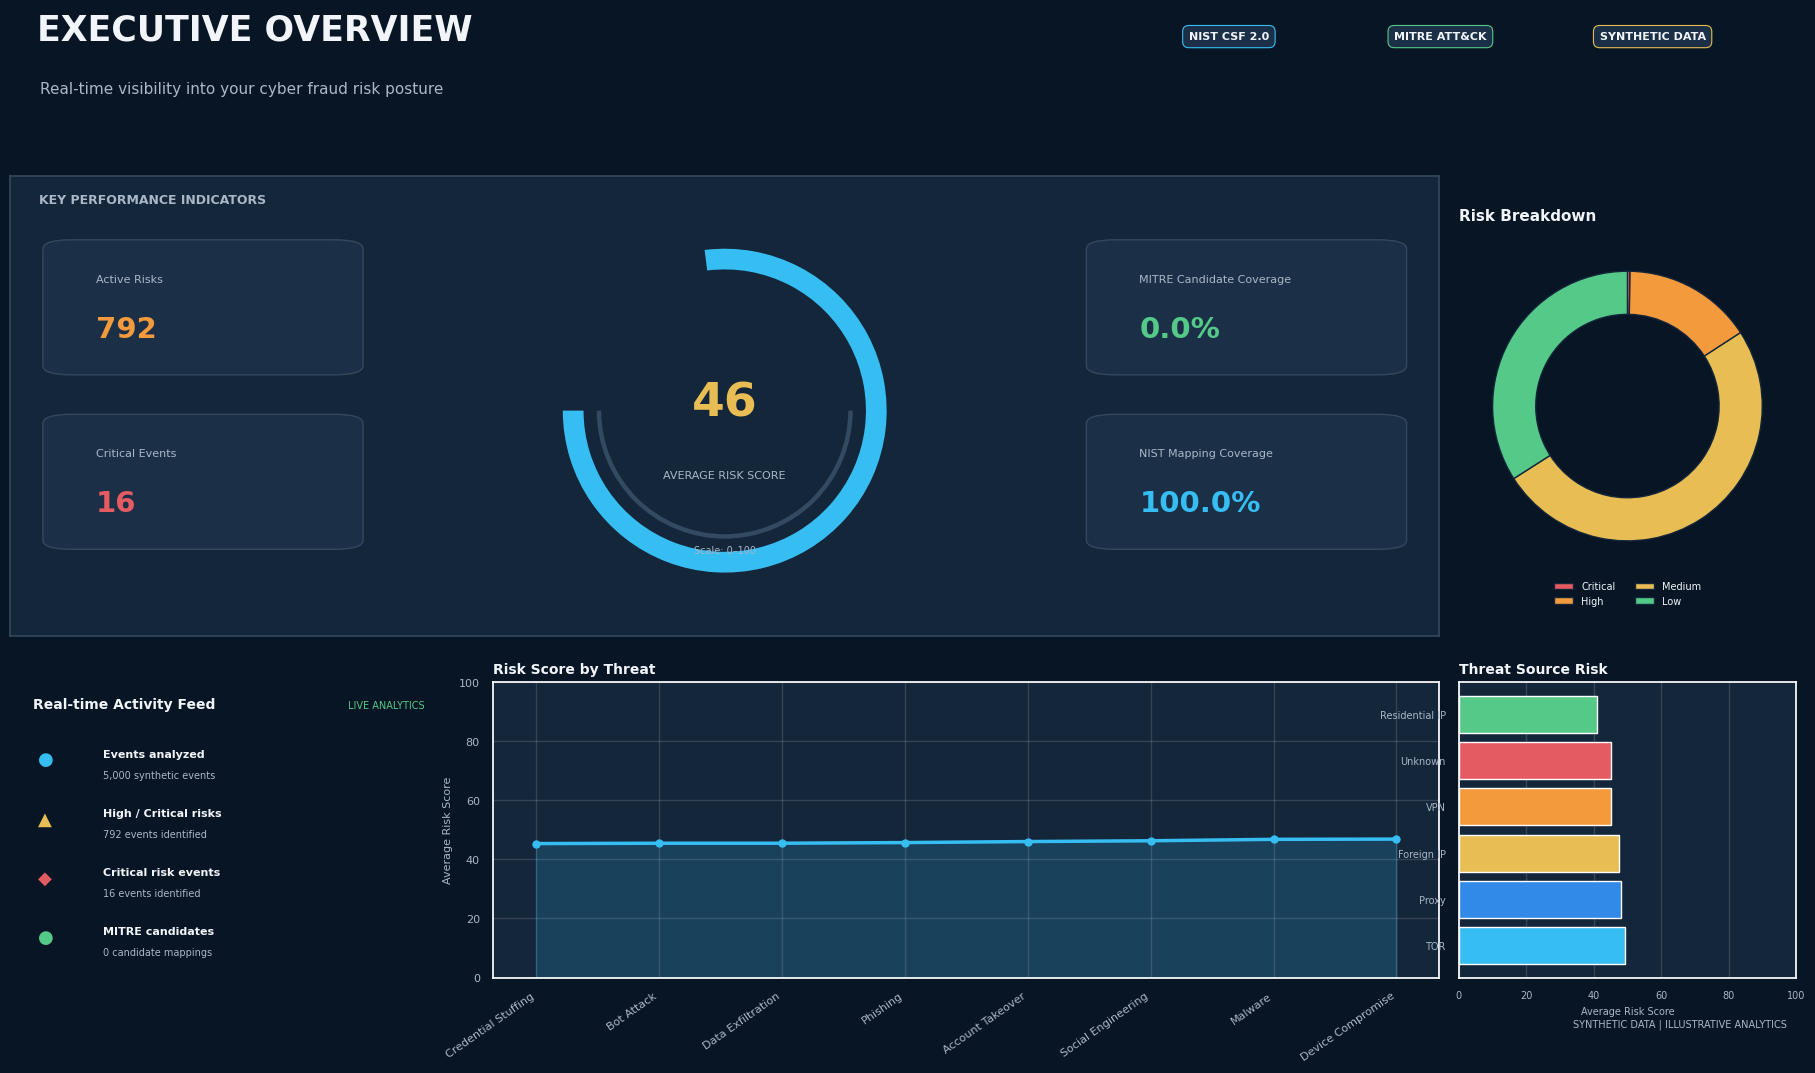

Executive Overview generated successfully.
Export: cyber_fraud_executive_overview.png


In [11]:


import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
import numpy as np
import pandas as pd

# =========================================================
# EXECUTIVE OVERVIEW | CYBER FRAUD INTELLIGENCE
# Visual inspirado na imagem de referência
# =========================================================

# Paleta visual
BG = "#071525"
PANEL = "#14263A"
PANEL_LIGHT = "#1B3047"
BORDER = "#34485D"
WHITE = "#F1F5F9"
MUTED = "#A9B7C7"
CYAN = "#36BDF2"
BLUE = "#3189E8"
GOLD = "#E7BD54"
GREEN = "#55C987"
ORANGE = "#F39A3D"
RED = "#E45B62"

sns.set_theme(style="dark")

# =========================================================
# PREPARAÇÃO DOS INDICADORES
# =========================================================

total_events = len(df)

high_critical = df[
    df["risk_classification"].isin(["High", "Critical"])
].shape[0]

critical_events = (
    df["risk_classification"] == "Critical"
).sum()

avg_risk = df["risk_score"].mean()

mitre_coverage = (
    df["mitre_mapping_status"].eq("Candidate mapping").mean() * 100
)

nist_coverage = df["nist_function"].notna().mean() * 100

risk_order = ["Critical", "High", "Medium", "Low"]

risk_counts = (
    df["risk_classification"]
    .value_counts()
    .reindex(risk_order, fill_value=0)
)

source_risk = (
    df.groupby("source")["risk_score"]
    .mean()
    .sort_values(ascending=False)
)

threat_risk = (
    df.groupby("threat_type")["risk_score"]
    .mean()
    .sort_values(ascending=True)
)

# =========================================================
# ESTRUTURA DO DASHBOARD
# =========================================================

fig = plt.figure(figsize=(19, 11), facecolor=BG)

gs = fig.add_gridspec(
    3, 4,
    height_ratios=[0.55, 2.1, 1.35],
    width_ratios=[1.1, 1.1, 1.1, 0.8],
    left=0.035,
    right=0.975,
    top=0.94,
    bottom=0.06,
    hspace=0.16,
    wspace=0.045
)

# =========================================================
# CABEÇALHO
# =========================================================

header = fig.add_subplot(gs[0, :])
header.set_facecolor(BG)
header.axis("off")

header.text(
    0.015, 0.75,
    "EXECUTIVE OVERVIEW",
    fontsize=25,
    fontweight="bold",
    color=WHITE,
    transform=header.transAxes
)

header.text(
    0.017, 0.30,
    "Real-time visibility into your cyber fraud risk posture",
    fontsize=11,
    color=MUTED,
    transform=header.transAxes
)

# Badges superiores
badges = [
    ("NIST CSF 2.0", CYAN),
    ("MITRE ATT&CK", GREEN),
    ("SYNTHETIC DATA", GOLD)
]

for i, (label, color) in enumerate(badges):
    header.text(
        0.66 + i * 0.115, 0.75,
        label,
        fontsize=8,
        color=WHITE,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.55",
            facecolor=PANEL_LIGHT,
            edgecolor=color,
            linewidth=0.8
        ),
        transform=header.transAxes
    )

# =========================================================
# PAINEL SUPERIOR DE KPIs
# =========================================================

kpi_panel = fig.add_subplot(gs[1, 0:3])
kpi_panel.set_facecolor(PANEL)
kpi_panel.set_xticks([])
kpi_panel.set_yticks([])
for spine in kpi_panel.spines.values():
    spine.set_color(BORDER)
    spine.set_linewidth(1.2)

kpi_panel.text(
    0.02, 0.94, "KEY PERFORMANCE INDICATORS",
    color=MUTED, fontsize=9, fontweight="bold",
    transform=kpi_panel.transAxes
)

# Cartões de KPI
def draw_kpi(ax, x, y, title, value, color):
    card = patches.FancyBboxPatch(
        (x, y), 0.20, 0.27,
        boxstyle="round,pad=0.012,rounding_size=0.02",
        facecolor=PANEL_LIGHT,
        edgecolor=BORDER,
        linewidth=1,
        transform=ax.transAxes
    )
    ax.add_patch(card)

    ax.text(
        x + 0.025, y + 0.19,
        title, fontsize=8, color=MUTED,
        transform=ax.transAxes
    )

    ax.text(
        x + 0.025, y + 0.07,
        value, fontsize=21, fontweight="bold",
        color=color, transform=ax.transAxes
    )

draw_kpi(
    kpi_panel, 0.035, 0.58,
    "Active Risks", f"{high_critical:,}", ORANGE
)

draw_kpi(
    kpi_panel, 0.035, 0.20,
    "Critical Events", f"{critical_events:,}", RED
)

draw_kpi(
    kpi_panel, 0.765, 0.58,
    "MITRE Candidate Coverage", f"{mitre_coverage:.1f}%", GREEN
)

draw_kpi(
    kpi_panel, 0.765, 0.20,
    "NIST Mapping Coverage", f"{nist_coverage:.1f}%", CYAN
)

# =========================================================
# GAUGE CENTRAL — AVERAGE RISK SCORE
# =========================================================

gauge_ax = kpi_panel.inset_axes([0.31, 0.08, 0.38, 0.82])
gauge_ax.set_facecolor(PANEL)
gauge_ax.set_aspect("equal")
gauge_ax.axis("off")

# Fundo do arco
gauge_ax.add_patch(
    patches.Wedge(
        (0.5, 0.5), 0.43, 180, 0,
        width=0.055,
        facecolor="#293E53",
        edgecolor="none"
    )
)

# Arco preenchido
gauge_value = np.clip(avg_risk, 0, 100)
angle = 180 - (gauge_value * 1.8)

gauge_ax.add_patch(
    patches.Wedge(
        (0.5, 0.5), 0.43, 180, angle,
        width=0.055,
        facecolor=CYAN,
        edgecolor="none"
    )
)

gauge_ax.add_patch(
    patches.Wedge(
        (0.5, 0.5), 0.34, 180, 0,
        width=0.012,
        facecolor="#344A60",
        edgecolor="none"
    )
)

gauge_color = (
    GREEN if avg_risk < 40
    else GOLD if avg_risk < 60
    else ORANGE if avg_risk < 80
    else RED
)

gauge_ax.text(
    0.5, 0.52,
    f"{avg_risk:.0f}",
    fontsize=34,
    fontweight="bold",
    color=gauge_color,
    ha="center",
    va="center"
)

gauge_ax.text(
    0.5, 0.32,
    "AVERAGE RISK SCORE",
    fontsize=8,
    color=MUTED,
    ha="center"
)

gauge_ax.text(
    0.5, 0.12,
    "Scale: 0–100",
    fontsize=7,
    color=MUTED,
    ha="center"
)

# =========================================================
# PAINEL LATERAL — RISK BREAKDOWN
# =========================================================

risk_ax = fig.add_subplot(gs[1, 3])
risk_ax.set_facecolor(PANEL)
risk_ax.set_title(
    "Risk Breakdown",
    loc="left", color=WHITE,
    fontsize=11, fontweight="bold", pad=12
)

risk_colors = [RED, ORANGE, GOLD, GREEN]

risk_ax.pie(
    risk_counts.values,
    colors=risk_colors,
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.32, edgecolor=PANEL)
)

risk_ax.legend(
    risk_counts.index,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    fontsize=7,
    frameon=False,
    labelcolor=WHITE
)

risk_ax.set_aspect("equal")

# =========================================================
# PAINEL INFERIOR ESQUERDO — ACTIVITY FEED
# =========================================================

feed_ax = fig.add_subplot(gs[2, 0])
feed_ax.set_facecolor(PANEL)
feed_ax.axis("off")

feed_ax.text(
    0.05, 0.91, "Real-time Activity Feed",
    color=WHITE, fontsize=10, fontweight="bold",
    transform=feed_ax.transAxes
)

feed_ax.text(
    0.73, 0.91, "LIVE ANALYTICS",
    color=GREEN, fontsize=7,
    transform=feed_ax.transAxes
)

activity_items = [
    ("●", "Events analyzed", f"{total_events:,} synthetic events"),
    ("▲", "High / Critical risks", f"{high_critical:,} events identified"),
    ("◆", "Critical risk events", f"{critical_events:,} events identified"),
    ("●", "MITRE candidates", f"{df['mitre_mapping_status'].eq('Candidate mapping').sum():,} candidate mappings")
]

for i, (symbol, title, detail) in enumerate(activity_items):
    y = 0.72 - i * 0.20

    feed_ax.text(
        0.06, y, symbol,
        fontsize=13,
        color=[CYAN, GOLD, RED, GREEN][i],
        transform=feed_ax.transAxes
    )

    feed_ax.text(
        0.20, y + 0.025, title,
        fontsize=8, color=WHITE,
        fontweight="bold",
        transform=feed_ax.transAxes
    )

    feed_ax.text(
        0.20, y - 0.045, detail,
        fontsize=7, color=MUTED,
        transform=feed_ax.transAxes
    )

# =========================================================
# PAINEL INFERIOR CENTRAL — SECURITY SCORE
# =========================================================

score_ax = fig.add_subplot(gs[2, 1:3])
score_ax.set_facecolor(PANEL)

score_ax.set_title(
    "Risk Score by Threat",
    loc="left", color=WHITE,
    fontsize=10, fontweight="bold"
)

x = np.arange(len(threat_risk))
y = threat_risk.values

score_ax.plot(
    x, y,
    color=CYAN,
    linewidth=2.5,
    marker="o",
    markersize=5
)

score_ax.fill_between(
    x, y, alpha=0.18,
    color=CYAN
)

score_ax.set_xticks(x)
score_ax.set_xticklabels(
    threat_risk.index,
    rotation=35,
    ha="right",
    fontsize=7,
    color=MUTED
)

score_ax.set_ylabel(
    "Average Risk Score",
    color=MUTED,
    fontsize=8
)

score_ax.tick_params(colors=MUTED, labelsize=8)
score_ax.grid(alpha=0.15, color=WHITE)
score_ax.set_ylim(0, 100)

# =========================================================
# PAINEL INFERIOR DIREITO — THREAT ORIGINS
# =========================================================

source_ax = fig.add_subplot(gs[2, 3])
source_ax.set_facecolor(PANEL)

source_ax.set_title(
    "Threat Source Risk",
    loc="left", color=WHITE,
    fontsize=10, fontweight="bold"
)

source_ax.barh(
    source_risk.index,
    source_risk.values,
    color=[CYAN, BLUE, GOLD, ORANGE, RED, GREEN][:len(source_risk)]
)

source_ax.set_xlim(0, 100)
source_ax.set_xlabel(
    "Average Risk Score",
    color=MUTED,
    fontsize=7
)

source_ax.tick_params(colors=MUTED, labelsize=7)
source_ax.grid(axis="x", alpha=0.15)
source_ax.set_axisbelow(True)

# =========================================================
# FINALIZAÇÃO
# =========================================================

for ax in fig.axes:
    ax.set_facecolor(PANEL)

fig.text(
    0.97, 0.015,
    "SYNTHETIC DATA | ILLUSTRATIVE ANALYTICS",
    color=MUTED,
    fontsize=7,
    ha="right"
)

plt.savefig(
    "cyber_fraud_executive_overview.png",
    dpi=220,
    facecolor=BG,
    bbox_inches="tight"
)

plt.show()

print("Executive Overview generated successfully.")
print("Export: cyber_fraud_executive_overview.png")

